In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

# Data info

In [ ]:
df = pd.read_csv(r"C:\Users\Hp\Desktop\mediclaim-app\data\mediclaim_raw.csv")

In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,61.0,female,21.09,0.0,no,northwest,13415.0381
1,46.0,male,42.35,3.0,yes,southeast,46151.1245
2,43.0,MALE,35.97,3.0,yes,southeast,42124.5153
3,51.0,male,39.7,1.0,no,southwest,9391.346
4,25.0,female,23.465,0.0,no,NORTHEAST,3206.49135


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1351 entries, 0 to 1350
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1331 non-null   object 
 1   sex       1324 non-null   object 
 2   bmi       1324 non-null   object 
 3   children  1331 non-null   float64
 4   smoker    1323 non-null   object 
 5   region    1324 non-null   object 
 6   charges   1343 non-null   object 
dtypes: float64(1), object(6)
memory usage: 74.0+ KB


In [ ]:
print(df.isna().sum())

age         20
sex         27
bmi         27
children    20
smoker      28
region      27
charges      8
dtype: int64


In [ ]:
print(df.duplicated().sum())

13


# Data cleaning

In [ ]:
# Standardize column names
df.columns = df.columns.str.strip().str.lower()

In [8]:
 # Convert numeric columns
numeric_cols = ["age", "bmi", "children", "charges"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [ ]:
# Clean categorical columns
for col in ["sex", "smoker", "region"]:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower())

In [10]:
# Standardize sex
df["sex"] = df["sex"].replace({
    "m": "male",
    "f": "female"})

In [ ]:
# Standardize smoker
df["smoker"] = df["smoker"].replace({
    "y": "yes",
    "n": "no"})

In [ ]:
# Standardize region
df["region"] = (
    df["region"]
    .str.replace(" ", "", regex=False))

In [13]:
# Validate categorical values
df.loc[
    ~df["sex"].isin(["male", "female"]), "sex"] = np.nan

df.loc[
    ~df["smoker"].isin(["yes", "no"]), "smoker"] = np.nan

valid_regions = [
        "northeast",
        "northwest",
        "southeast",
        "southwest"]

In [14]:
df.loc[~df["region"].isin(valid_regions), "region"] = np.nan

In [ ]:
# Handle invalid numeric values
df.loc[(df["age"] < 0) | (df["age"] > 100),"age"] = np.nan

df.loc[(df["bmi"] <= 0) | (df["bmi"] > 80),"bmi"] = np.nan

df.loc[df["children"] < 0,"children"] = np.nan

In [16]:
# Invalid insurance charges
df.loc[df["charges"] <= 0,"charges"] = np.nan

In [17]:
# Remove rows where target is missing
df = df.dropna(subset=["charges"])

# Cleaned data

In [18]:
df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,61.0,female,21.090,0.0,no,northwest,13415.03810
1,46.0,male,42.350,3.0,yes,southeast,46151.12450
2,43.0,male,35.970,3.0,yes,southeast,42124.51530
3,51.0,male,39.700,1.0,no,southwest,9391.34600
4,25.0,female,23.465,0.0,no,northeast,3206.49135
5,50.0,female,27.600,1.0,yes,<NA>,24520.26400
6,19.0,female,25.745,1.0,no,northwest,2710.82855
7,31.0,male,27.645,2.0,no,northeast,5031.26955
8,19.0,female,30.590,2.0,no,northwest,24059.68019
9,29.0,female,29.590,1.0,no,southeast,3947.41310


# EDA

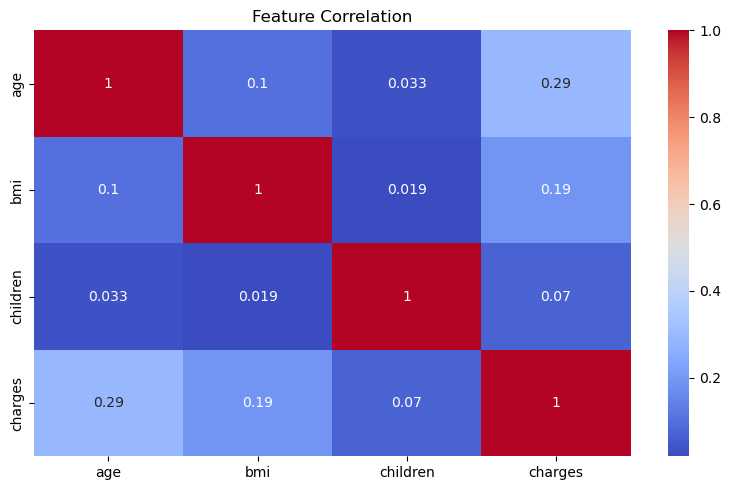

In [19]:
# Correlation analysis
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm")

plt.title("Feature Correlation")
plt.tight_layout()
plt.show()

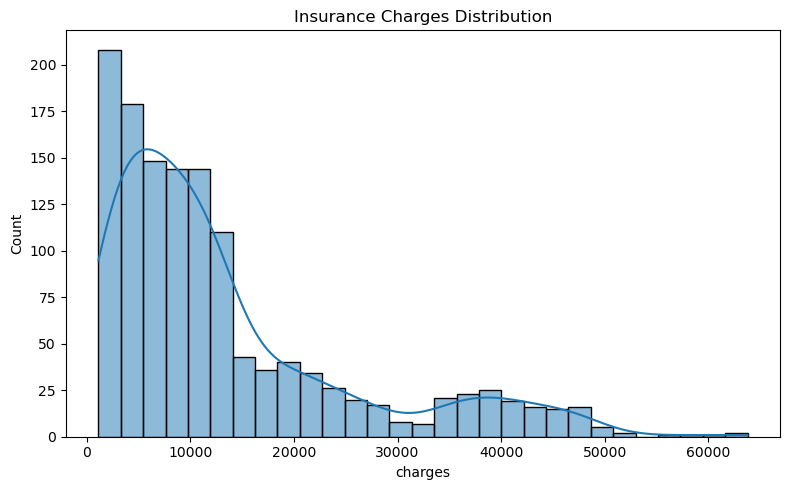

In [20]:
# Charges distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    df["charges"],
    kde=True
)

plt.title("Insurance Charges Distribution")
plt.tight_layout()
plt.show()

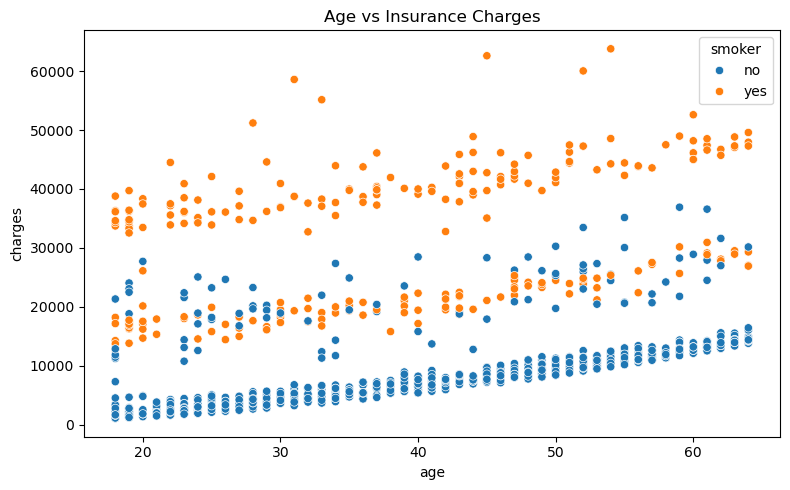

In [21]:
# Age vs charges
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker"
)

plt.title("Age vs Insurance Charges")
plt.tight_layout()
plt.show()

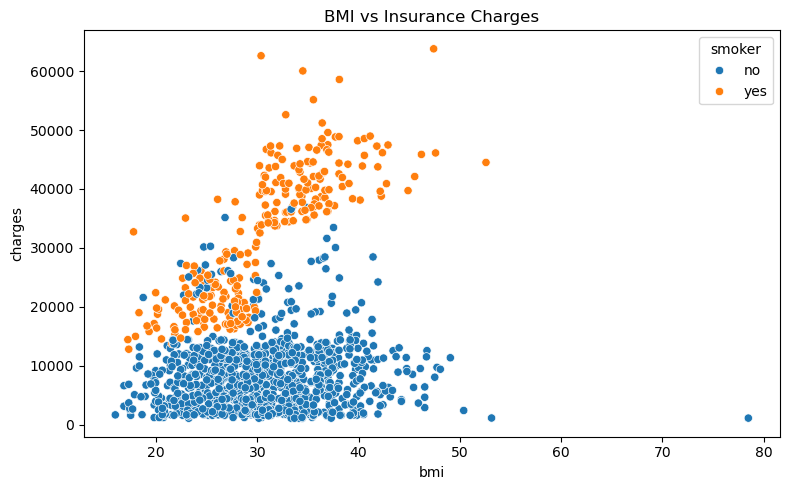

In [22]:
# BMI vs charges
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)

plt.title("BMI vs Insurance Charges")
plt.tight_layout()
plt.show()

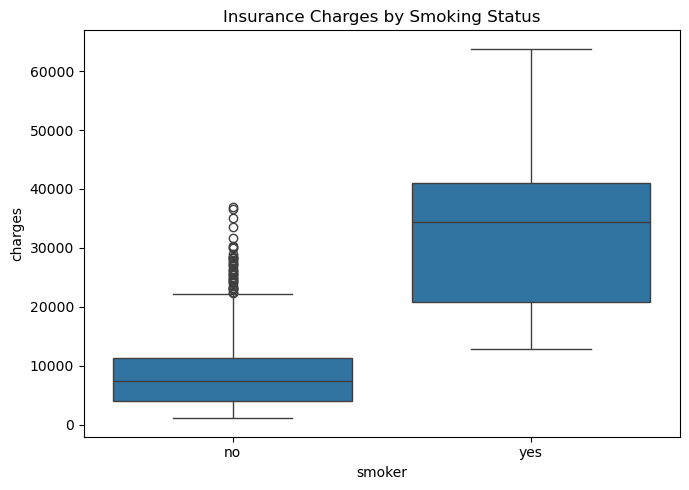

In [23]:
# Smoker comparison
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="charges"
)

plt.title("Insurance Charges by Smoking Status")
plt.tight_layout()
plt.show()

In [24]:
# DEFINE FEATURES AND TARGET
X = df.drop(columns=["charges"])

y = df["charges"]

numerical_features = ["age","bmi","children"]

categorical_features = ["sex","smoker","region"]

In [ ]:
#  TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    test_size=0.20,
    random_state=42)

In [26]:
X_train

,age,sex,bmi,children,smoker,region
204,31.0,male,36.300,2.0,yes,southwest
363,34.0,male,35.815,0.0,no,northwest
422,25.0,female,NaN,1.0,no,southeast
300,61.0,male,36.100,3.0,no,southwest
10,19.0,male,17.480,0.0,no,northwest
...,...,...,...,...,...,...
1126,48.0,male,29.700,0.0,no,southeast
1164,34.0,male,21.375,0.0,no,northeast
1334,63.0,male,36.765,0.0,no,northeast
885,63.0,male,21.660,1.0,no,northwest


# Featuring Engineering

In [27]:
# NUMERICAL PIPELINE
numeric_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median"))])


# 5. CATEGORICAL PIPELINE
categorical_pipeline = Pipeline([("imputer",
        SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))])

In [28]:
# COLUMN TRANSFORMER
preprocessor = ColumnTransformer([
    ("num",numeric_pipeline,numerical_features),
    ("cat",categorical_pipeline,categorical_features)])

In [29]:
model_pipeline = Pipeline([("preprocessor",preprocessor),
    ("model",RandomForestRegressor(
            n_estimators=400,
            max_depth=None,
            min_samples_split=2,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1))])

In [30]:
# Convert pandas nullable strings containing <NA>
X_train_clean = X_train.astype(object).fillna(np.nan)
X_test_clean = X_test.astype(object).fillna(np.nan)


#  MODEL TRAINING
model_pipeline.fit(X_train_clean, y_train)

C:\Users\Hp\AppData\Local\Temp\ipykernel_4756\4106920983.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train_clean = X_train.astype(object).fillna(np.nan)
C:\Users\Hp\AppData\Local\Temp\ipykernel_4756\4106920983.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test_clean = X_test.astype(object).fillna(np.nan)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['age', 'bmi', 'children']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['sex', 'smoker',
                                                   'region'])])),
                ('model',
                 RandomForestRegressor(min_samples_leaf=2, n_estimators=400,
                                       n_jobs=-1, random_state=42))])

In [31]:
 # MODEL PREDICTION
 y_pred = model_pipeline.predict(X_test_clean)

In [32]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))

print("MSE:", round(mse, 2))

print("RMSE:", round(rmse, 2))

print("R2 Score:", round(r2, 4))

MAE: 2863.7
MSE: 25655148.35
RMSE: 5065.09
R2 Score: 0.8057


### Test Model on New Data Points

In [33]:
# new hypothetical data points
new_customers = pd.DataFrame([
    {
        "age": 25.0,
        "sex": "female",
        "bmi": 22.5,
        "children": 0.0,
        "smoker": "no",
        "region": "northeast"
    },
    {
        "age": 45.0,
        "sex": "male",
        "bmi": 35.2,
        "children": 2.0,
        "smoker": "yes",
        "region": "southeast"
    },
    {
        "age": 60.0,
        "sex": "female",
        "bmi": 28.0,
        "children": 1.0,
        "smoker": "no",
        "region": "northwest"
    }
])


new_customers_clean = new_customers.astype(object).fillna(np.nan)

C:\Users\Hp\AppData\Local\Temp\ipykernel_4756\934378233.py:30: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  new_customers_clean = new_customers.astype(object).fillna(np.nan)


In [34]:

# Make predictions
predicted_charges = model_pipeline.predict(new_customers_clean)

In [35]:
new_customers["predicted_charges"] = np.round(predicted_charges, 2)
display(new_customers)

,age,sex,bmi,children,smoker,region,predicted_charges
0,25.0,female,22.5,0.0,no,northeast,6543.80
1,45.0,male,35.2,2.0,yes,southeast,43392.12
2,60.0,female,28.0,1.0,no,northwest,15773.70


### Pickle the Trained Model Pipeline

In [36]:
import pickle

# Save the pipeline to a local .pkl file using pickle
with open('insurance_model_pipeline.pkl', 'wb') as f:
    pickle.dump(model_pipeline, f)

print("Model pipeline successfully pickled to 'insurance_model_pipeline.pkl'")

Model pipeline successfully pickled to 'insurance_model_pipeline.pkl'


In [37]:
import joblib
import os

# Create the models directory as expected by the Streamlit app
os.makedirs("models", exist_ok=True)

# Save the model pipeline using joblib
model_save_path = "models/insurance_model_pipeline.pkl"
joblib.dump(model_pipeline, model_save_path)

print(f"Model pipeline successfully saved using joblib to '{model_save_path}'!")

Model pipeline successfully saved using joblib to 'models/insurance_model_pipeline.pkl'!


In [38]:
# Test loading the model using joblib to verify it works exactly as the Streamlit app will load it
loaded_model = joblib.load("models/insurance_model_pipeline.pkl")
test_predictions = loaded_model.predict(new_customers_clean)
print("Loaded model predictions:", test_predictions)

Loaded model predictions: [ 6543.79833882 43392.11790892 15773.69519349]
